# DC4 511 keV Imaging and Residual Analysis

This notebook runs the complete imaging workflow in one kernel: it combines the weekly observations, prepares the simulated background and detector response, reconstructs the 511 keV sky, evaluates the fitted source and background expectations, and calculates residual diagnostics directly from the in-memory histograms. No intermediate residual-product file is required.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Environment and imports

The following cells locate the workflow directory, import the imaging and residual-analysis interfaces, and load the centralized input paths.

In [2]:
# Locate the workflow root so local modules can be imported.
from pathlib import Path
import sys

working_dir = Path.cwd()
repo_root = (
    working_dir.parent 
    if working_dir.name == "notebooks"
    else working_dir
)
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [3]:
import cosipy as cp

from cosipy.image_deconvolution import DataIF_COSI_DC2, ImageDeconvolution
from histpy import Histogram
from src import path_to_files as paths
from src.residuals import ResidualAnalysis
from src.plot_residuals import PlottingResiduals
from src.time_resolved_residuals_v1 import TemporalPredictionBuilder

%matplotlib inline


## 2. Observed 511 keV data

Each weekly product contains a time-resolved event histogram. The full weekly `(Time, Em, Phi, PsiChi)` histograms are added first to retain `Observed_temporal_counts` ($D_{t,i}$). Projecting out time then gives `observed_atemporal_counts` ($D_i$), used by the imaging fit through the existing `observed_event_hist` name.

In [4]:
# Load every weekly binned observation.
analysis511 = {}
for week in paths.weekly_paths:
    output_path = paths.data_dir_out / f"dc4_week_{week}_511_binned.hdf5"
    analysis511[week] = cp.BinnedData(paths.config_511_path)
    analysis511[week].load_binned_data_from_hdf5(
        binned_data=str(output_path)
    )


In [5]:
# Copy the first full histogram to preserve the original weekly data.
observed_weeks = list(paths.weekly_paths)
Observed_temporal_counts = analysis511[observed_weeks[0]].binned_data.copy()

# Add the remaining weekly histograms while retaining the Time axis.
for week in observed_weeks[1:]:
    Observed_temporal_counts = (
        Observed_temporal_counts + analysis511[week].binned_data
    )

# Sum over time to obtain the atemporal counts used by the imaging fit.
observed_event_hist = (
    Observed_temporal_counts
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)


## 3. Simulated background

The background-only simulation is projected onto the same CDS axes as the observation. Its normalization remains part of the image-deconvolution result.

In [6]:
# Load the time-resolved simulated background.
simulated_background = cp.BinnedData(paths.config_511_path)
simulated_background.load_binned_data_from_hdf5(
    binned_data=str(paths.simulated_background_511_binned_path)
)
simulated_background_hist = simulated_background.binned_data


In [7]:
# Project the background onto the CDS coordinates used by the fit.
simulated_bg_counts_all = (
    simulated_background_hist
    .project("Em", "Phi", "PsiChi")
    .to_dense(copy=False)
)


## 4. Imaging response and data interface

Combine the precomputed Galactic response and the observed/background histograms in the COSI image-deconvolution data interface.


In [8]:
# Load the precomputed extended-source response.
response_511 = Histogram.open(
    str(paths.data_ext_response511_path)
)

In [9]:
# Build the image-deconvolution data interface.
data_interface = DataIF_COSI_DC2.load(
    name="511keV",
    event_binned_data=observed_event_hist,
    dict_bkg_binned_data={"background": simulated_bg_counts_all},
    rsp=response_511,
    coordsys_conv_matrix=None,
)


In [10]:
# Select the image-deconvolution configuration.
yml_file = paths.config_deconvo_path

In [11]:
# Configure the reconstruction with the simulated-background dataset.
image_deconvolution = ImageDeconvolution()

# Register the prepared data interface.
image_deconvolution.set_dataset([data_interface])
# Load the reconstruction parameters.
image_deconvolution.read_parameterfile(yml_file)

## 5. Image deconvolution

This is the computational fit. The final iteration contains both the reconstructed sky image and the fitted background normalization required to evaluate the expected CDS counts.

In [12]:
image_deconvolution.initialize()
image_deconvolution.run_deconvolution()
image_deconvolution.results

  0%|          | 0/15 [00:00<?, ?it/s]

[{'iteration': 1,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x124379850>,
  'background_normalization': {'background': 1.0961076123758495},
  'log-likelihood': [2266291.1040600436],
  'accel_factor': 1.0},
 {'iteration': 2,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x12496a2b0>,
  'background_normalization': {'background': 1.0952079248005853},
  'log-likelihood': [2267105.066573919],
  'accel_factor': 10.0},
 {'iteration': 3,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x12497b850>,
  'background_normalization': {'background': 1.0863005902917515},
  'log-likelihood': [2268141.8285720265],
  'accel_factor': 10.0},
 {'iteration': 4,
  'model': <cosipy.image_deconvolution.models.allskyimage.AllSkyImageModel at 0x1249796d0>,
  'background_normalization': {'background': 1.0777807213964938},
  'log-likelihood': [2269398.1521391096],
  'accel_factor': 10.0},
 {'iteration': 5,
  'model': <

## 6. Evaluate the fitted CDS expectation

Fold the final reconstructed sky and fitted background normalization through the same data interface to obtain the expected CDS counts.


In [13]:
# Read the fitted quantities from the final reconstruction iteration.
final_result = image_deconvolution.results[-1]
fitted_image = final_result["model"]
fitted_background_norm = final_result["background_normalization"]

# Fold the fitted sky and background models into the observed CDS bins.
source_expectation = data_interface.calc_source_expectation(fitted_image)
background_expectation = data_interface.calc_bkg_expectation(
    fitted_background_norm
)
total_expectation = data_interface.calc_expectation(
    fitted_image,
    fitted_background_norm,
)

## 7. Residual analysis from in-memory histograms

Pass the integrated observation and fitted total expectation directly to `ResidualAnalysis`.


In [14]:
# Associate the in-memory histograms with their analysis roles.
residual_analysis = ResidualAnalysis(
    observed=observed_event_hist,
    expected=total_expectation,
)


Observed data have no time information; using atemporal residual analysis.


### 7.1 Time-integrated residual plots

Show one-dimensional raw residuals and an angular Pearson-residual map from the fitted expectation.


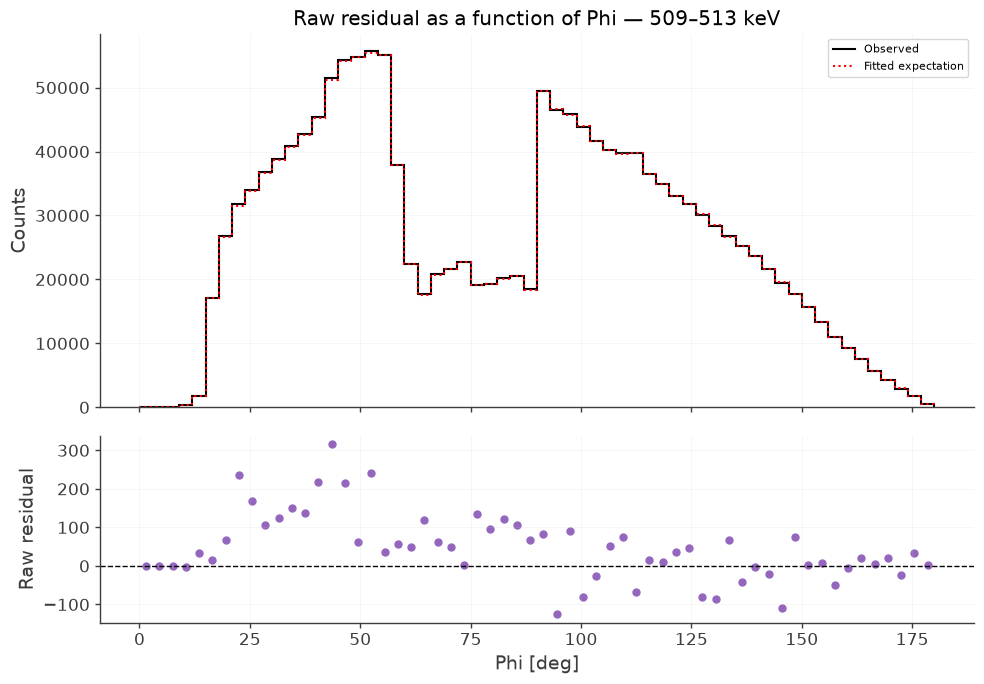


WARNING UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



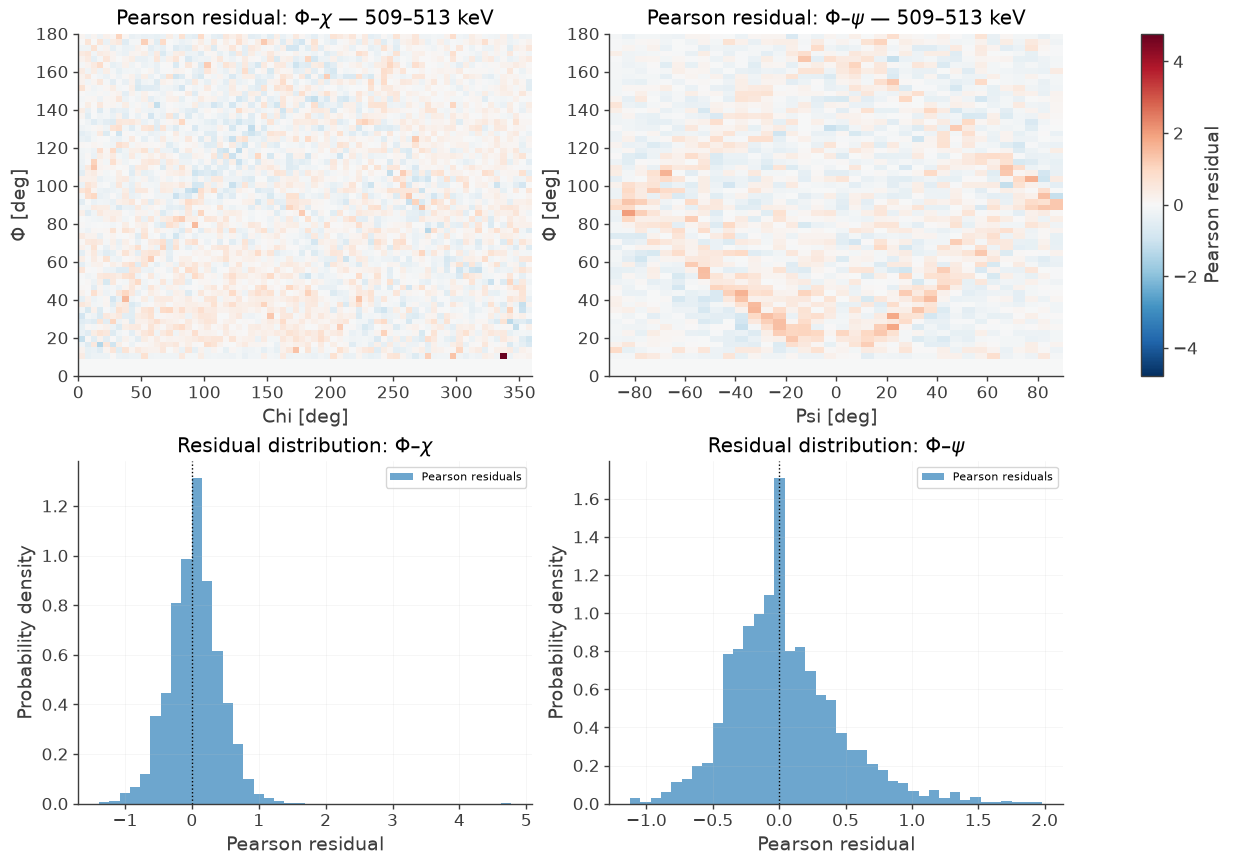

In [15]:
# Configure the plotting interface.
residual_plotter = PlottingResiduals(residual_analysis)

# Compare observed and expected counts along the Phi projection.
phi_raw_figure = residual_plotter.plot(
    "Phi_projection",
    residual_type="raw",
)

# Show the angular Pearson-residual maps.
angular_pearson_figure = residual_plotter.plot(
    "Phi_Chi_projection",
    residual_type="pearson",
    show_gaussian_reference=False,
)


## 8. Temporal residual analysis with a physical prediction

Fold the fitted sky through the detector response for each selected interval and scale the time-binned background with the fitted normalization.


In [16]:
# Prepare the temporal class using the observed counts and integrated model axes.
physical_temporal_analysis = TemporalPredictionBuilder(
    observed=Observed_temporal_counts,
    integrated_expected=total_expectation,
)
orientation = cp.SpacecraftHistory.open(paths.data_ori_path)


In [17]:
# Configure the physical temporal model.
physical_temporal_analysis.configure_physical_model(
    fitted_sky=fitted_image,
    response_path=paths.data_response511_path,
    orientation=orientation,
    temporal_background=simulated_background_hist,
    background_normalization=fitted_background_norm["background"],
    earth_occ=True,
)


### 8.1 Build matching temporal histograms

Select five consecutive original time bins and build their physical expectations.


In [18]:
# Select five consecutive original time bins.
first_time_bin = 13
stop_time_bin = first_time_bin + 5
selected_observed_temporal, selected_expected_temporal = (
    physical_temporal_analysis.build_physical_time_range(
        start=first_time_bin,
        stop=stop_time_bin,
    )
)


### 8.2 Temporal residual plots

Pass the matching temporal histograms to `ResidualAnalysis`, then show residuals across time and for one selected interval.


In [19]:
# Initialize the temporal residual analysis with the prepared physical products.
temporal_analysis = ResidualAnalysis(
    observed=selected_observed_temporal,
    expected=selected_expected_temporal,
)
temporal_plotter = PlottingResiduals(temporal_analysis)


Observed data contain time information; using temporal residual analysis.


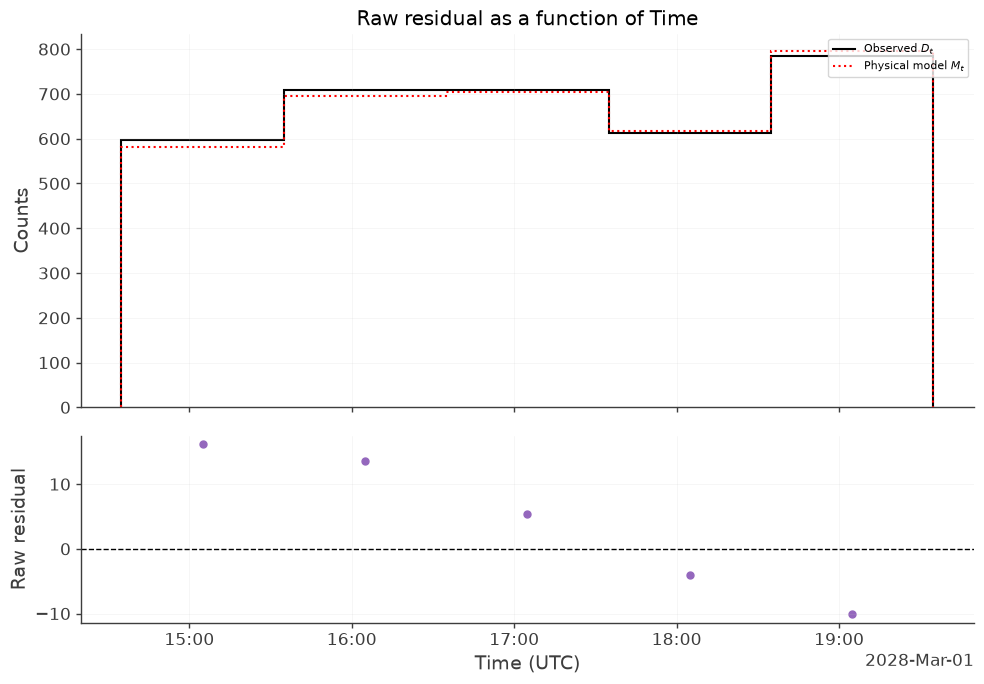

In [20]:
# Compare observed and expected counts and raw residuals over time.
time_raw_figure = temporal_plotter.plot(
    "Time_projection",
    residual_type="raw",
    show_uncertainty=False,
)


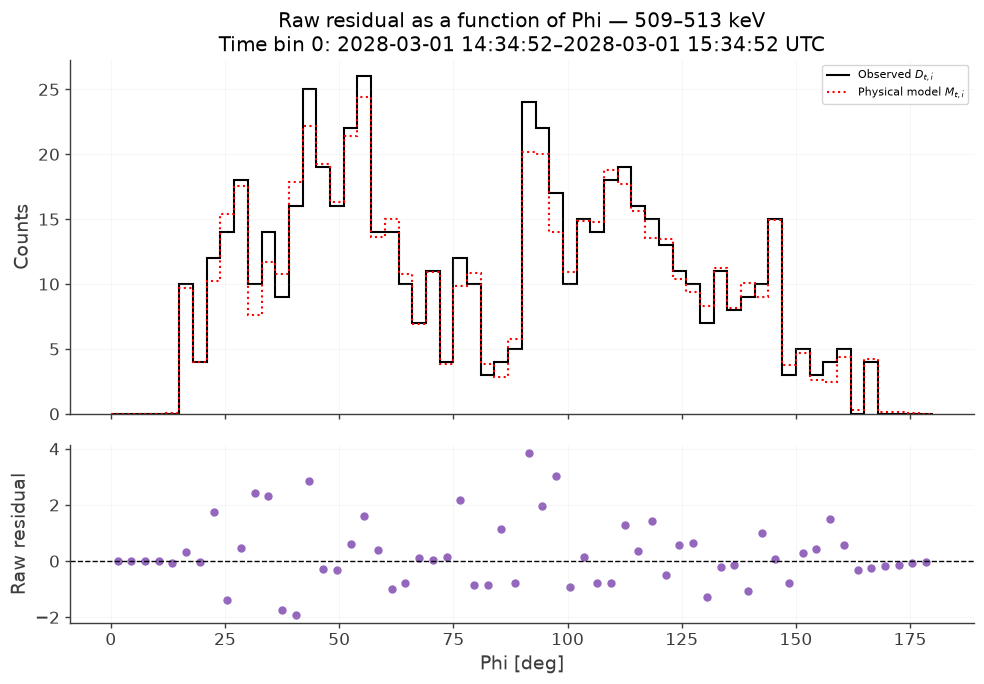

In [21]:
# Select the first prepared interval without refolding.
selected_temporal_analysis = temporal_analysis.select_time_bin(0)
selected_temporal_plotter = PlottingResiduals(selected_temporal_analysis)

# Compare observed and expected counts and raw residuals as a function of Phi.
selected_phi_figure = selected_temporal_plotter.plot(
    "Phi_projection",
    residual_type="raw",
    show_uncertainty=False,
)
